# Mutation statistics
* Group by: period, mutator background
* Metrics:
    * Genic, intergenic, promoters
    * Essential (genic, intergenic)
    * Syn or nonsyn

In [1]:
source('../../../R/preamble.R')

In [2]:
tid_to_mutator_bg = read.tsv('../../../datasets/genomics/06_mutators/results/tid_to_mutator_bg.tsv')
v = read.tsv('../../../datasets/genomics/04_gene_attribution/results/v.tsv') %>% left_join(tid_to_mutator_bg)

bw = 4
periods = seq(0, 24, bw) # course of the experiment
conf = 0.95 # For bayesian confidence intervals

# Make groups
v = v %>%
    filter(chrom == 'U00096', nchar(pop) == 1) %>%
    mutate(
        period = 2.5 * (periods[cut(gen, periods, label = F)] + bw / 2),
        mutator = ifelse(mutator_bg %in% c('None', 'Reverted'), 'Non-mutator', mutator_bg),
        segment = ifelse(target_type == 'intergenic', 'Intergenic', 'Intragenic')
    )

# Chromosomal footprints
position_to_context = read.tsv('../../../datasets/genomics/04_gene_attribution/intermediate/position_to_context.tsv') %>%
    filter(chrom == 'U00096')

context_to_footprint = position_to_context %>%
    mutate(footprint = (end - start + 1)) %>% 
    select(context, context_part, footprint)

# Mutator's mutation rates
mutator_to_mutation_rate = read.tsv('../../../datasets/genomics/06_mutators/results/mutator_to_mutation_rate.tsv')

Joining with `by = join_by(pop, tid)`


mutator,mutation_rate,mutation_rate_se,mu,mu_wt,mu_rel
<chr>,<dbl>,<dbl>,<(err)>,<(err)>,<(err)>
Non-mutator,0.8865992,0.03831598,0.89(4),0.89(4),1.00(6)
pMutS,3.8659503,0.27575771,3.9(3),0.89(4),4.4(4)
mutL(Δ6),7.5074025,1.83621853,8(2),0.89(4),8(2)
mutS(G696E),35.7101580,5.75228850,36(6),0.89(4),40(7)


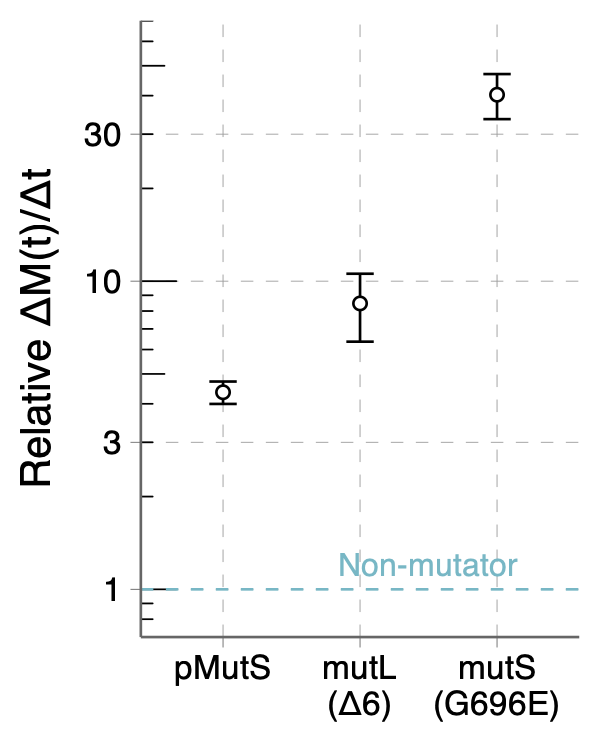

In [3]:
library(errors)

size(2.5, 2)
lwd = 0.3
w_color = pal[2]

mutator_to_mutation_rate_eb =
mutator_to_mutation_rate %>%
    mutate(
        mu = set_errors(mutation_rate, mutation_rate_se),
        mu_wt = mu[mutator == 'Non-mutator'],
        mu_rel = mu / mu_wt
    )

mutator_to_mutation_rate_eb

mutator_to_mutation_rate_eb %>% filter(mutator!='Non-mutator') %>% 
    mutate(mutator = gsub('(', '\n(', mutator, fixed=T)) %>% 

ggplot() + aes(
    x = fct_reorder(mutator, mutation_rate),
    y = mu_rel, ymin = errors_min(mu_rel), ymax = errors_max(mu_rel)
    ) +
    geom_errorbar(width=0.2, lwd=lwd) + 
    geom_point(pch=21, fill=w, stroke=lwd*1.5, size=1.2) +
    scale_y_log10(limits=c(0.7, 70), expand=expansion(mult=0)) + logticks('l') +
    theme(
        axis.title.x = eb,
        axis.text.x = element_text(color=b, size=8, hjust=0.5, angle=0)
    ) +

    geom_hline(lwd=lwd, lty=2, yintercept = 1, col=w_color) +
    add_text(2.5, 1.1, 'Non-mutator', color=w_color, size=2.7, hjust=0.5, vjust=0) +
    labs(x = 'Background', y = 'Relative ΔM(t)/Δt')

psave('Plots/deltaM_deltat')

## Genic vs intergenic
Only on SNPs.

In [4]:
# Null distribution
segment_to_footprint =
position_to_context %>%
    mutate(segment = ifelse(target_type == 'intergenic', 'Intergenic', 'Intragenic')) %>% 
    group_by(segment) %>% summarise(footprint = sum(end - start + 1)) %>%
    ungroup() %>% mutate(f_footprint = footprint / sum(footprint))

ig_f_footprint = segment_to_footprint[segment_to_footprint$segment == 'Intergenic',]$f_footprint

In [5]:
fraction_intergenic =
v %>%

    # Only count SNPs -- taking indels into account makes the enrichment stronger, but that just reflects the fact that indels in ORFs cause frameshifts
    filter(type == 'SNP', pop == origin) %>% 

    mutate(
        mutator = ifelse(mutator_bg %in% c('None', 'Reverted'), 'Non-mutator', mutator_bg),
    ) %>% 

    # Count mutations
    group_by(segment, mutator) %>% 
    summarise(n_mut = n_distinct(vid)) %>%
    group_by(mutator) %>% mutate(
        n_total = sum(n_mut), 
        f_mut = n_mut / n_total
    ) %>% 
    rowwise() %>% 
    mutate(
        f_mut_low = binom_hdi_low(n_mut, n_total, conf),
        f_mut_high = binom_hdi_high(n_mut, n_total, conf),
    ) %>% ungroup() %>% 
    arrange(mutator, segment) %>% 

    # Add neutral
    left_join(segment_to_footprint) %>% 
    filter(segment == 'Intergenic') %>%
    mutate(
        p_value = 2*pmin(pbinom(n_mut, n_total, f_footprint), pbinom(n_mut - 1, n_total, f_footprint, lower.tail = F))
        
    ) %>% 

    # Add mutation rates
    left_join(mutator_to_mutation_rate) %>% 
    mutate(
        p_value_adj = p.adjust(p_value, method='holm'), # Holm-Bonferroni adjustment
        f_exp = f_footprint,
        f_obs = f_mut
    )

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by segment and mutator.
ℹ Output is grouped by segment.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(segment, mutator))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


Joining with `by = join_by(segment)`


Joining with `by = join_by(mutator)`


Why are there fewer intergenic mutations than expected by chance in hyper-mutators?

# Essential genes

In [6]:
# Map intergenic regions to the genes they affect
ig_to_first_gene = read.tsv('../../../datasets/genomics/05_genome_mapping/results/ig_to_first_gene.tsv') %>% filter(chrom == 'U00096')

# Get list of essential genes
name_to_essential = read.tsv('../../../datasets/genomics/external_datasets/Essential_genes/gene_name_to_essential.tsv')

# Find which intergenic regions affect at least one essential gene
context_to_essential_ig = 
    ig_to_first_gene %>% 
    separate_rows(affected, sep = ',') %>%
    left_join(name_to_essential) %>%
    group_by(context, context_part) %>%
    summarise(essential = any(essential %in% c('unclear', 'essential')))

context_to_essential_g =
    position_to_context %>% 
    filter(target_type != 'intergenic') %>% 
    mutate(affected = context) %>% separate_rows(affected, sep = '\\|') %>%
    left_join(name_to_essential) %>% 
    group_by(context, context_part) %>%
    summarise(essential = any(essential %in% c('unclear', 'essential')))

context_to_essential_all = rbind(
    context_to_essential_ig,
    context_to_essential_g
)

Joining with `by = join_by(affected)`


`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by context and context_part.
ℹ Output is grouped by context.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(context, context_part))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


Joining with `by = join_by(affected)`


`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by context and context_part.
ℹ Output is grouped by context.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(context, context_part))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


In [7]:
essential_to_footprint =
    context_to_footprint %>%
    left_join(context_to_essential_all) %>%
    group_by(essential) %>%
    summarise(footprint = sum(footprint)) %>%
    ungroup() %>% 
    mutate(f_footprint = footprint / sum(footprint))

essential_f_footprint = essential_to_footprint[essential_to_footprint$essential == TRUE,]$f_footprint
essential_f_footprint

Joining with `by = join_by(context, context_part)`


[1] 0.1770755

In [8]:
fraction_essential =
v %>%
    left_join(context_to_essential_all) %>% 

    # Count mutations
    group_by(essential, mutator) %>% 
    summarise(n_mut = n_distinct(vid)) %>%
    group_by(mutator) %>% mutate(
        n_total = sum(n_mut), 
        f_mut = n_mut / n_total
    ) %>% 
    rowwise() %>% 
    mutate(
        f_mut_low = binom_hdi_low(n_mut, n_total, conf),
        f_mut_high = binom_hdi_high(n_mut, n_total, conf),        
    ) %>% ungroup() %>% 
    arrange(mutator, essential) %>% 

    # Add neutral
    left_join(essential_to_footprint) %>% 
    filter(essential) %>%
    mutate(
        p_value = 2*pmin(pbinom(n_mut, n_total, f_footprint), pbinom(n_mut - 1, n_total, f_footprint, lower.tail = F))
        
    ) %>% 

    # Add mutation rates
    left_join(mutator_to_mutation_rate) %>% 
    mutate(
        p_value_adj = p.adjust(p_value, method='holm'), # Holm-Bonferroni adjustment
        f_exp = f_footprint,
        f_obs = f_mut
    )

fraction_essential

Joining with `by = join_by(context)`


Warning message in left_join(., context_to_essential_all):
“Detected an unexpected many-to-many relationship between `x` and `y`.
ℹ Row 119 of `x` matches multiple rows in `y`.
ℹ Row 5701 of `y` matches multiple rows in `x`.
ℹ If a many-to-many relationship is expected, set `relationship =
  "many-to-many"` to silence this warning.”


`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by essential and mutator.
ℹ Output is grouped by essential.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(essential, mutator))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


Joining with `by = join_by(essential)`


Joining with `by = join_by(mutator)`


essential,mutator,n_mut,n_total,f_mut,f_mut_low,f_mut_high,footprint,f_footprint,p_value,mutation_rate,mutation_rate_se,p_value_adj,f_exp,f_obs
<lgl>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
TRUE,Non-mutator,198,841,0.2354340,0.2072944,0.2645541,821923,0.1770755,2.293858e-05,0.8865992,0.03831598,9.175434e-05,0.1770755,0.2354340
TRUE,mutL(Δ6),90,442,0.2036199,0.1672360,0.2420913,821923,0.1770755,1.651633e-01,7.5074025,1.83621853,1.651633e-01,0.1770755,0.2036199
TRUE,mutS(G696E),801,5031,0.1592129,0.1492114,0.1694258,821923,0.1770755,8.319523e-04,35.7101580,5.75228850,2.495857e-03,0.1770755,0.1592129
TRUE,pMutS,79,332,0.2379518,0.1935523,0.2848051,821923,0.1770755,6.139083e-03,3.8659503,0.27575771,1.227817e-02,0.1770755,0.2379518


# Fraction synonymous
Only take regions with no overlapping features into account.

In [9]:
tid_to_codon_sub_coding = read.tsv('../../../datasets/genomics/06_mutators/results/Codon_substitution_observed/tid_to_codon_sub_coding.tsv') %>% select(tid, meaning, codon_ref, codon_alt)
tid_to_codon_sub_noncoding = read.tsv('../../../datasets/genomics/06_mutators/results/Codon_substitution_observed/tid_to_codon_sub_noncoding.tsv') %>% select(tid, meaning, codon_ref, codon_alt)
tid_to_codon_sub = rbind(tid_to_codon_sub_coding, tid_to_codon_sub_noncoding)

genetic_code = read.tsv('../../../datasets/genomics/06_mutators/results/genetic_code.tsv')
codon_to_aa = setNames(genetic_code$aa, genetic_code$codon)

In [10]:
size(2, 4)

mutator_bg_to_syn =
    tid_to_codon_sub %>%
    mutate(pop = substr(tid, 1, 1)) %>% 
    left_join(tid_to_mutator_bg) %>% 
    mutate(mutator = ifelse(mutator_bg %in% c('None', 'Reverted'), 'Non-mutator', mutator_bg)) %>% 

    # Translate
    mutate(
        aa_ref = codon_to_aa[codon_ref],
        aa_alt = codon_to_aa[codon_alt]
        ) %>% 

    group_by(mutator) %>%
    summarise(
        n_syn_real = sum(aa_ref == aa_alt & meaning == 'real'),
        n_alt_real = sum(aa_ref != aa_alt & meaning == 'real'),
        n_syn_artif = sum(aa_ref == aa_alt & meaning == 'artificial'),
        n_alt_artif = sum(aa_ref != aa_alt & meaning == 'artificial'),
        n_total_real = sum(meaning == 'real'),
        n_total_artif = sum(meaning == 'artificial')
    ) %>% 
    ungroup() %>% 

    # Get posteriors
    mutate(
        #r_obs = binom
        f_obs = n_alt_real / n_total_real,
        f_exp = n_alt_artif / n_total_artif
        ) %>%

    rowwise() %>% 
    mutate(
        f_obs_low = binom_hdi_low(n_alt_real, n_total_real, conf),
        f_obs_high = binom_hdi_high(n_alt_real, n_total_real, conf),        
    ) %>% ungroup() %>% 

    ungroup() %>% complete(nesting(mutator), fill = list(f_obs = 0, f_exp = 1, n_total_real = 0)) %>% 

    left_join(
        mutator_to_mutation_rate
    )

mutator_bg_to_syn = mutator_bg_to_syn %>% rowwise() %>% 

    mutate(
        p_value = prop.test(
          x = c(n_alt_real, n_alt_artif),
          n = c(n_total_real, n_total_artif)
        )$p.value
    ) %>% ungroup() %>% 

    # Holm-Bonferroni adjustment
    mutate(
        p_value_adj = p.adjust(p_value, method='holm')
    )

Joining with `by = join_by(tid, pop)`


Joining with `by = join_by(mutator)`


### Promoters

In [11]:
# Base-R function to find hits
is_in_region <- function(positions, starts, ends, names) {

    # For each position, find which interval it falls into
    idx <- findInterval(positions, starts)

    # Check if position is actually within the end boundary
    
    ifelse(idx > 0 & positions <= ends[idx], names[idx], NA)
}

# Promoter dataset
promoter_regions_cut = read.tsv('../../../datasets/genomics/external_datasets/New/promoter_regions_cut.tsv') %>% arrange(start)

# Get footprints
promoter_fp = (promoter_regions_cut %>% summarise(sum(end - start + 1)))[[1]]
genome_size = sum(context_to_footprint$footprint)
promoter_expected_ratio = promoter_fp / genome_size
promoter_expected_ratio

fraction_in_promoters = v %>%
    filter(type %in% c('SNP')) %>% 
    mutate(
        region = is_in_region(pos, promoter_regions_cut$start, promoter_regions_cut$end, promoter_regions_cut$name),
        in_promoter = !is.na(region)
    ) %>% 

    # Count mutations
    group_by(in_promoter, mutator) %>% 
    summarise(n_mut = n_distinct(vid)) %>%
    group_by(mutator) %>% mutate(
        n_total = sum(n_mut), 
        f_mut = n_mut / n_total
    ) %>% 
    rowwise() %>% 
    mutate(
        f_mut_low = binom_hdi_low(n_mut, n_total, conf),
        f_mut_high = binom_hdi_high(n_mut, n_total, conf),        
    ) %>% ungroup() %>% 
    arrange(mutator, in_promoter) %>% 

    # Add neutral
    filter(in_promoter) %>%
    mutate(
        p_value = 2*pmin(pbinom(n_mut, n_total, promoter_expected_ratio), pbinom(n_mut - 1, n_total, promoter_expected_ratio, lower.tail = F))
        
    ) %>% 

    # Add mutation rates
    left_join(mutator_to_mutation_rate) %>% 
    mutate(
        p_value_adj = p.adjust(p_value, method='holm'), # Holm-Bonferroni adjustment
        f_exp = promoter_expected_ratio,
        f_obs = f_mut
    )

[1] 0.05281805

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by in_promoter and mutator.
ℹ Output is grouped by in_promoter.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(in_promoter, mutator))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


Joining with `by = join_by(mutator)`


### Plot against mutation frequency

In [12]:
contrast = pal[1]
lwd = 0.3
sz = 1.5

ar = arrow = arrow(length = unit(4, 'pt'), type = 'open')
x_lab = 'Mutation rate (/kgen)'

In [13]:
syn_mut_plot =
mutator_bg_to_syn %>% 

ggplot() + aes(
    y = f_obs*100,
    x = mutation_rate, xmin = mutation_rate - mutation_rate_se, xmax = mutation_rate + mutation_rate_se,
    label = case_when(p_value_adj < 0.05 ~ '★', T ~ '')
    ) +

    geom_segment(
        aes(y = f_exp*100, yend = f_obs*100-sign(f_obs-f_exp)*1),
        col=contrast, lwd=lwd, arrow=ar
    ) +
    geom_point(
        aes(y = f_exp*100), 
        size=sz, pch=21, fill=pal[2], col=contrast
    ) +

    #geom_errorbar(width = 0.2, lwd=lwd) +
    geom_point(
        size=sz, pch=21, fill=w, stroke=lwd
    ) +

    # Significance stars
    geom_text(
        aes(y = f_obs*100 + 1.6*sign(f_obs-f_exp)),
        size=1.5, col=b, hjust=0.5
    ) +

    small_text + small_titles +
    scale_x_log10(limits=c(3e-1, 0.9e2)) + logticks('b') +
    ycont(56, 86) +
    labs(x = 'Mutation rate (/1000 gen.)', y = 'Non-syn. (%)')

In [14]:
ig_mut_plot =
fraction_intergenic %>% 

ggplot() + aes(
    y = f_obs*100,
    x = mutation_rate, xmin = mutation_rate - mutation_rate_se, xmax = mutation_rate + mutation_rate_se,
    label = case_when(p_value_adj < 0.05 ~ '★', T ~ '')
    ) +

    geom_segment(
        aes(y = f_exp*100, yend = f_obs*100-sign(f_obs-f_exp)*1),
        col=contrast, lwd=lwd, arrow=ar
    ) +
    geom_point(
        aes(y = f_exp*100), 
        size=sz, pch=21, fill=pal[2], col=contrast
    ) +

    geom_point(
        size=sz, pch=21, fill=w, stroke=lwd
    ) +

    # Significance stars
    geom_text(
        aes(y = f_obs*100 + 1.6*sign(f_obs-f_exp)),
        size=1.5, col=b, hjust=0.5
    ) +

    small_text + small_titles +
    scale_x_log10(limits=c(3e-1, 0.9e2)) + logticks('b') +
    ycont(0, 30) +
    labs(x = 'Mutation rate (/1000 gen.)', y = 'Intergenic SNPs (%)')

In [15]:
ess_mut_plot =
fraction_essential %>% 

ggplot() + aes(
    y = f_obs*100,
    x = mutation_rate, xmin = mutation_rate - mutation_rate_se, xmax = mutation_rate + mutation_rate_se,
    label = case_when(p_value_adj < 0.05 ~ '★', T ~ '')
    ) +

    geom_segment(
        aes(y = f_exp*100, yend = f_obs*100-sign(f_obs-f_exp)*1),
        col=contrast, lwd=lwd, arrow=ar
    ) +
    geom_point(
        aes(y = f_exp*100), 
        size=sz, pch=21, fill=pal[2], col=contrast
    ) +
    geom_point(
        size=sz, pch=21, fill=w, stroke=lwd
    ) +

    # Significance stars
    geom_text(
        aes(y = f_obs*100 + 1.6*sign(f_obs-f_exp)),
        size=1.5, col=b, hjust=0.5
    ) +

    small_text + small_titles +
    scale_x_log10(limits=c(3e-1, 0.9e2)) + logticks('b') +
    logticks('b') + ycont(0, 30) +
    labs(x = 'Mutation rate (/1000 gen.)', y = 'Essential genes (%)')

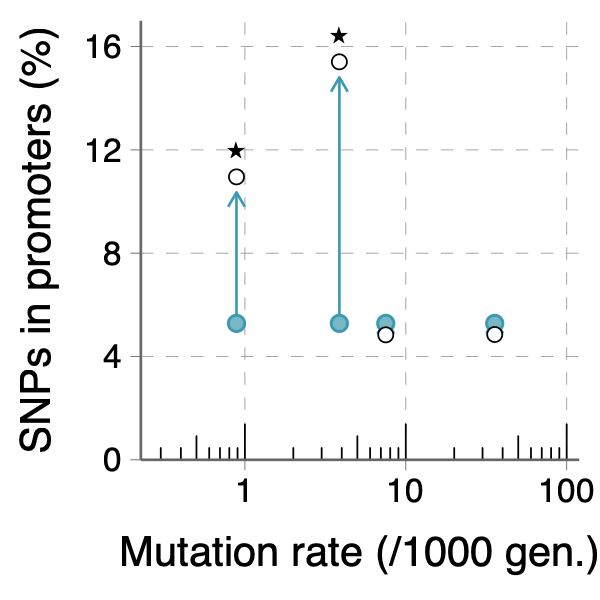

In [16]:
prom_mut_plot =
fraction_in_promoters %>% 

ggplot() + aes(
    y = f_obs*100,
    x = mutation_rate, xmin = mutation_rate - mutation_rate_se, xmax = mutation_rate + mutation_rate_se,
    label = case_when(p_value_adj < 0.05 ~ '★', T ~ '')
    ) +

    geom_segment(
        aes(y = f_exp*100, yend = f_obs*100-sign(f_obs-f_exp)*0.6),
        col=contrast, lwd=lwd, arrow=ar
    ) +
    geom_point(
        aes(y = f_exp*100), 
        size=sz, pch=21, fill=pal[2], col=contrast
    ) +
    geom_point(
        size=sz, pch=21, fill=w, stroke=lwd
    ) +

    # Significance stars
    geom_text(
        aes(y = f_obs*100 + 1*sign(f_obs-f_exp)),
        size=1.5, col=b, hjust=0.5
    ) +

    #xlog(2e-1, 0.9e2, breaks=c() + 
    scale_x_log10(limits=c(3e-1, 0.9e2)) + logticks('b') +
    ycont(0, 17) +
    small_text + small_titles +
    labs(x = 'Mutation rate (/1000 gen.)', y = 'SNPs in promoters (%)')

size(2, 2.5) # wide enough for the full x-axis title, which was clipped at 2 in
prom_mut_plot
psave('Plots/prom_mut_plot')

In [17]:
saveRDS(ig_mut_plot, 'Plots/GG/ig_enrichment.rds')
saveRDS(ess_mut_plot, 'Plots/GG/ess_enrichment.rds')
saveRDS(syn_mut_plot, 'Plots/GG/syn_enrichment.rds')

saveRDS(prom_mut_plot, 'Plots/GG/prom_enrichment.rds')

In [18]:
# Load the pos_to_region function
library(reticulate)
source_python('../05_genome_mapping/region_to_pos.py')